<a href="https://colab.research.google.com/github/CrisDev96/Proyecto-Programacion-RN-Grupo3/blob/main/07MIAR_Proyecto_Programacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Enunciado

En esta actividad, el alumno debe **evaluar y comparar dos estrategias** para la **clasificación de imágenes** empleando el **dataset asignado**. El/La alumnx deberá resolver el reto proponiendo una solución válida **basada en aprendizaje profundo**, más concretamente en redes neuronales convolucionales (**CNNs**). Será indispensable que la solución propuesta siga el **pipeline visto en clase** para resolver este tipo de tareas de inteligencia artificial:

1.   **Carga** del conjunto de datos
2.   **Inspección** del conjunto de datos
3.   **Acondicionamiento** del conjunto de datos
4.   Desarrollo de la **arquitectura** de red neuronal y **entrenamiento** de la solución
5.   **Monitorización** del proceso de **entrenamiento** para la toma de decisiones
6.   **Evaluación** del modelo predictivo y planteamiento de la siguiente prueba experimental

### Estrategia 1: Entrenar desde cero o *from scratch*

La primera estrategia a comparar será una **red neuronal profunda** que el **alumno debe diseñar, entrenar y optimizar**. Se debe **justificar empíricamente** las decisiones que llevaron a la selección de la **arquitectura e hiperparámetros final**. Se espera que el alumno utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

### Estrategia 2: Red pre-entrenada

La segunda estrategia a comparar debe incluir la utilización de una **red preentrenada** con el dataset ImageNet, llevando a cabo tareas de ***transfer learning*** y ***fine-tuning*** para resolver la tarea de clasificación asignada. Deben **compararse al menos dos tipos de arquitecturas** (VGGs, ResNet50, Xception, InceptionV3, InceptionResNetV2, MobileNetV2, DenseNet, ResNet) y se debe **seleccionar la que mayor precisión proporcione** (información sobre las arquitecturas disponibles en https://keras.io/applications/). Se espera que el/la alumnx utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

## Normas a seguir

- Será **indispensable** realizar el **trabajo por parejas**. Dichas parejas de alumnxs se generarán **de manera automática** teniendo en cuenta el pais de residencia con el objetivo de facilitar el trabajo en equipo.  
- Se debe entregar un **ÚNICO FICHERO PDF POR ALUMNO** que incluya las instrucciones presentes en el Colab Noteboook y su **EJECUCIÓN!!!**. Debe aparecer todo el proceso llevado a cabo en cada estrategia (i.e. carga de datos, inspección de datos, acondicionamiento, proceso de entrenamiento y proceso de validación del modelo).
- **La memoria del trabajo** (el fichero PDF mencionado en el punto anterior) deberá **subirla cada integrante del grupo** (aunque se trate de un documento idéntico) a la actividad que se habilitará **en CampusVIU**.
- Se recomienda trabajar respecto a un directorio base (**BASE_FOLDER**) para facilitar el trabajo en equipo. En este notebook se incluye un ejemplo de cómo almacenar/cargar datos utilizando un directorio base.
- Las **redes propuestas** deben estar **entrenadas** (y **EVIDENCIAR este proceso en el documento PDF**). La entrega de una **red sin entrenar** supondrá **perdida de puntos**.
- Si se desea **evidenciar alguna métrica** del proceso de entrenamiento (precisión, pérdida, etc.), estas deben ser generadas.
- Todos los **gráficos** que se deseen mostrar deberán **generarse en el Colab Notebook** para que tras la conversión aparezcan en el documento PDF.

## *Tips* para realizar la actividad con éxito
- Los **datos** se cargarán directamente **desde** la plataforma **Kaggle** mediante su API (https://github.com/Kaggle/kaggle-api). En este Notebook se incluye un ejemplo de como hacerlo. Se recomienda generar una función que aborde esta tarea.
- El **documento PDF a entregar** como solución de la actividad se debe **generar automáticamente desde el fichero ".ipynb"**. En este Notebook se incluye un ejemplo de como hacerlo.
- **Generar secciones y subsecciones en el Colab Notebook** supondrá que el documento **PDF generado** queda totalmente **ordenado** facilitando la evaluación al docente.
- Se recomienda encarecidamente **incluir comentarios concisos pero aclaratorios**.
- Es muy recomendable crear una **última sección** de texto en el Colab Notebook en la que se discutan los diferentes modelos obtenidos y se extraigan las conclusiones pertinentes.

## Criterios de evaluación

- **Seguimiento** de las **normas establecidas** en la actividad (detalladas anteriormente).
- Creación de una **solución que resuelva la tarea de clasificación**, i.e. que las figuras de mérito empleadas para medir la bondad del modelo predictivo evidencien un *performance* superior al rendimiento estocástico.
- **Claridad** en la creación de la solución, en las justificaciones sobre la toma de decisiones llevada a cabo así como en las comparativas y conclusiones finales.
- **Efectividad** al presentar las comparaciones entre métricas de evaluación de ambas estrategias.
- **Demostración** de la utilización de **técnicas de regularización** para mejorar el rendimiento de los modelos.

In [12]:
#Librerias

import kagglehub
import os
import matplotlib.pyplot as plt
from PIL import Image
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split

## Cargando datos del dataset de la plataforma Kaggle

In [6]:
# Descarga del dataset basandonos en Keagglehub
path = kagglehub.dataset_download("hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'shoe-vs-sandal-vs-boot-dataset-15k-images' dataset.
Path to dataset files: /kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images


In [7]:
#Mostrar contenido del dataset

for elemento in os.listdir(path):
    ruta = os.path.join(path, elemento)

    if os.path.isdir(ruta):
        print(f"Carpeta: {elemento}")
        print("Subcarpetas:", os.listdir(ruta))
    else:
        print(f"Archivo: {elemento}")

Carpeta: Shoe vs Sandal vs Boot Dataset
Subcarpetas: ['Shoe', 'Sandal', 'Boot']


In [8]:
# Buscar las carpetas de las clases
for root, dirs, files in os.walk(path):
    if files:
        imagenes = [
            f for f in files
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        if imagenes:
            print(f"Carpeta: {root}")
            print(f"Cantidad de imágenes: {len(imagenes)}")
            print("-" * 40)

Carpeta: /kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Boot Dataset/Shoe
Cantidad de imágenes: 5000
----------------------------------------
Carpeta: /kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Boot Dataset/Sandal
Cantidad de imágenes: 5000
----------------------------------------
Carpeta: /kaggle/input/shoe-vs-sandal-vs-boot-dataset-15k-images/Shoe vs Sandal vs Boot Dataset/Boot
Cantidad de imágenes: 5000
----------------------------------------


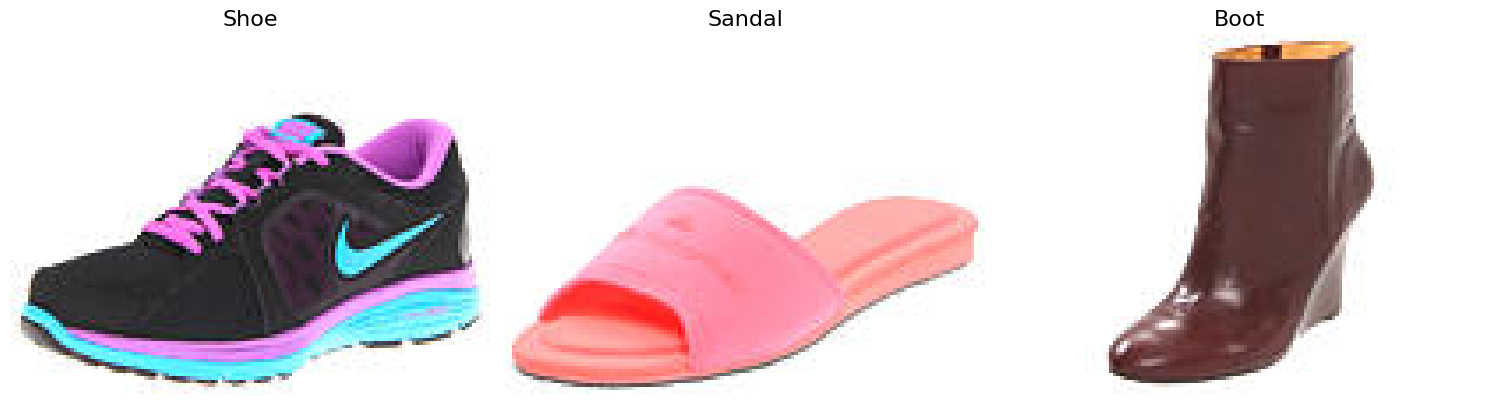

In [11]:
dataset_path = path

# Buscar las imágenes de cada clase
clases = ['Shoe', 'Sandal', 'Boot']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, clase in enumerate(clases):

    # Buscar la carpeta correspondiente a la clase
    carpeta_clase = None

    for root, dirs, files in os.walk(dataset_path):
        if os.path.basename(root).lower() == clase.lower():
            carpeta_clase = root
            break

    # Obtener las imágenes
    imagenes = [
        f for f in os.listdir(carpeta_clase)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    # Seleccionar una imagen aleatoria
    imagen_seleccionada = random.choice(imagenes)

    # Abrir imagen
    ruta_imagen = os.path.join(carpeta_clase, imagen_seleccionada)
    imagen = Image.open(ruta_imagen)

    # Mostrar imagen
    axes[i].imshow(imagen)
    axes[i].set_title(clase, fontsize=16)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Acondicionamineto de Datos del DataSet

El objetivo del acondicionamiento es preparar las imágenes para que posteriormente podamos entrenar un modelo de Machine Learning o Deep Learning.

In [15]:

# Diccionario de clases y etiquetas
clases_a_etiquetas = {
    'Shoe': 0,
    'Sandal': 1,
    'Boot': 2
}

# Listas para almacenar las rutas y etiquetas
image_paths = []
image_labels = []

# Recorrer las clases
for clase in clases:

    # Buscar la carpeta correspondiente
    carpeta_clase = None

    for root, dirs, files in os.walk(dataset_path):
        if os.path.basename(root).lower() == clase.lower():
            carpeta_clase = root
            break

    # Recorrer las imágenes de la carpeta
    for archivo in os.listdir(carpeta_clase):

        if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_paths.append(
                os.path.join(carpeta_clase, archivo)
            )

            image_labels.append(clases_a_etiquetas[clase])

# Convertir a arrays de NumPy
image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total de imágenes:", len(image_paths))
print("Total de etiquetas:", len(image_labels))

Total de imágenes: 15000
Total de etiquetas: 15000


## División de conjunto de datos

In [17]:
# Primera división: 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# Segunda división: 15% validación y 15% pruebas
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Imágenes de entrenamiento:", len(X_train))
print("Imágenes de validación:", len(X_val))
print("Imágenes de prueba:", len(X_test))

Imágenes de entrenamiento: 10500
Imágenes de validación: 2250
Imágenes de prueba: 2250


## Normalización de imagenes

In [18]:
# Tamaño de las imágenes
IMG_SIZE = (150, 150)

def preprocesar_imagen(image_path, label):

    # Leer imagen
    imagen = tf.io.read_file(image_path)

    # Convertir a RGB
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False
    )

    imagen.set_shape([None, None, 3])

    # Redimensionar
    imagen = tf.image.resize(imagen, IMG_SIZE)

    # Normalizar
    imagen = imagen / 255.0

    return imagen, label


In [19]:
# Tamaño de los lotes
BATCH_SIZE = 32

# Función para crear los datasets
def crear_dataset(paths, labels, entrenamiento=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        preprocesar_imagen,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Crear los tres conjuntos
train_dataset = crear_dataset(X_train, y_train, entrenamiento=True)
val_dataset = crear_dataset(X_val, y_val)
test_dataset = crear_dataset(X_test, y_test)

print("Conjunto de datos creaado")

Conjunto de datos creaado


## Revisar conjunto de datos despúes del acondicionamiento

In [20]:
# Obtener un lote de entrenamiento
imagenes, etiquetas = next(iter(train_dataset))

print("Dimensiones del lote:", imagenes.shape)
print("Tipo de datos:", imagenes.dtype)
print("Valor mínimo:", tf.reduce_min(imagenes).numpy())
print("Valor máximo:", tf.reduce_max(imagenes).numpy())

Dimensiones del lote: (32, 150, 150, 3)
Tipo de datos: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0


Este resultado representa el batch size 32, las dos dimensiones de las imagenes alto y ancho 150 pixeles, y 3 que representa la escala RGB.

## Ejemplo de generación de documento PDF a partir del Colab Notebook (fichero ".ipynb")

In [ ]:
# Ejecutando los siguientes comandos en la última celda del Colab Notebook se convierte de ".ipynb" a PDF
# En caso de querer ocultar la salida de una celda puesto que no tenga relevancia se debe insertar
# el comando %%capture al inicio de la misma. Véase la celda que contiene !ls test en este Notebook.

In [ ]:
name_IPYNB_file = '07MIAR_Proyecto_Programacion.ipynb'
get_ipython().system(
        "apt update >> /dev/null && apt install texlive-xetex texlive-fonts-recommended texlive-generic-recommended >> /dev/null"
    )
get_ipython().system(
            "jupyter nbconvert --output-dir='$BASE_FOLDER' '$BASE_FOLDER''$name_IPYNB_file' --to pdf"
        )





[NbConvertApp] Converting notebook /content/drive/MyDrive/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Programacion.ipynb to pdf
[NbConvertApp] Support files will be in 07MIAR_Proyecto_Programacion_files/
[NbConvertApp] Making directory ./07MIAR_Proyecto_Programacion_files
[NbConvertApp] Writing 43232 bytes to ./notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: [u'xelatex', u'./notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: [u'bibtex', u'./notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 179055 bytes to /content/drive/MyDrive/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Programacion.pdf
